# Customer & Product Unit Economics
Contribution-margin analysis from the engine snapshot `reporting.customer_economics_monthly`. The application's own cost-allocation engine writes that table, so these figures match the dashboards. Demo data is **synthetic**.

In [1]:
import os, pandas as pd, matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
# Read-only analysis. Set DATABASE_URL (e.g. the powerbi_reader role) before running; never hard-code credentials.
engine = create_engine(os.environ["DATABASE_URL"], connect_args={"options": "-c TimeZone=UTC"})
q = lambda sql, **p: pd.read_sql(text(sql), engine, params=p)
plt.rcParams.update({"figure.facecolor": "#050b1c", "axes.facecolor": "#0b1330", "axes.edgecolor": "#1e2c5a", "text.color": "#e6ecff",
                     "axes.labelcolor": "#e6ecff", "xtick.color": "#8b98bd", "ytick.color": "#8b98bd", "figure.figsize": (10, 4)})
pd.options.display.float_format = "{:,.2f}".format

## 1. Validation: segment classification follows the documented thresholds
PROFITABLE ≥ 15% · AT_RISK 0–15% · UNPROFITABLE < 0%.

In [2]:
e = q("SELECT * FROM reporting.customer_economics_monthly e JOIN reporting.dim_customer d USING (customer_id, tenant_id)")
def seg(m):
    return "UNPROFITABLE" if m < 0 else "AT_RISK" if m < 15 else "PROFITABLE"
withm = e.dropna(subset=["margin_pct"])
bad = withm[withm.margin_pct.astype(float).map(seg) != withm.profitability]
assert bad.empty, bad
assert ((e.net_revenue - e.direct_cost - e.contribution).abs() < 0.005).all()
print(f"{len(e)} customer-months validated")

1064 customer-months validated


## 2. Portfolio margin trend

,net_revenue,direct_cost,contribution,margin_pct
month_start,,,,
2026-05-01,"11,046,851.34","7,555,005.02","3,491,846.32",31.61
2026-06-01,"11,116,406.97","7,573,034.78","3,543,372.19",31.88
2026-07-01,"11,881,680.42","7,376,552.04","4,505,128.38",37.92
2026-08-01,"11,371,461.75","7,572,490.08","3,798,971.67",33.41
2026-09-01,"11,595,932.62","7,387,280.05","4,208,652.57",36.29
2026-10-01,"12,701,586.81","7,663,063.01","5,038,523.80",39.67


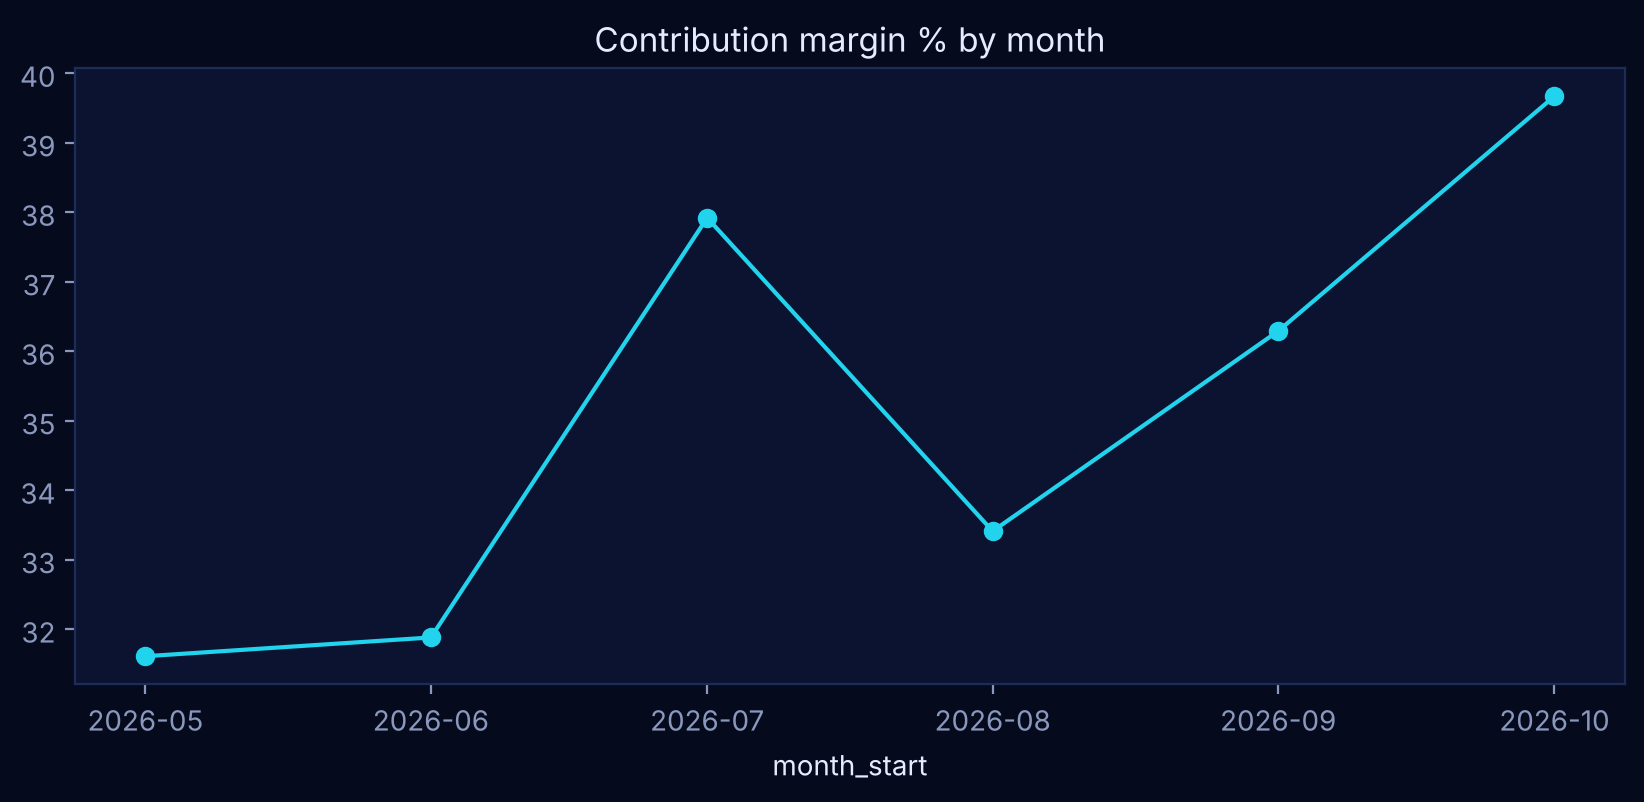

In [3]:
m = e.groupby("month_start")[["net_revenue", "direct_cost", "contribution"]].sum()
m["margin_pct"] = (m.contribution / m.net_revenue * 100).round(2)
m.margin_pct.plot(marker="o", color="#22d3ee", title="Contribution margin % by month")
m

## 3. Profitability by segment

In [4]:
seg_df = q(open("../sql/04_profitability_by_segment.sql").read())
latest = seg_df[seg_df.month_start == seg_df.month_start.max()]
latest

,month_start,segment,customers,revenue,direct_cost,contribution,margin_pct,unprofitable
15,2026-10-01,ENTERPRISE,79,"9,536,217.86","5,190,608.12","4,345,609.74",45.57,6
16,2026-10-01,MID_MARKET,62,"2,687,559.54","1,962,370.17","725,189.37",26.98,9
17,2026-10-01,SMB,51,"477,809.41","510,084.72","-32,275.31",-6.75,11


profitability
PROFITABLE      157
UNPROFITABLE     26
AT_RISK           6
NO_REVENUE        3
Name: count, dtype: int64

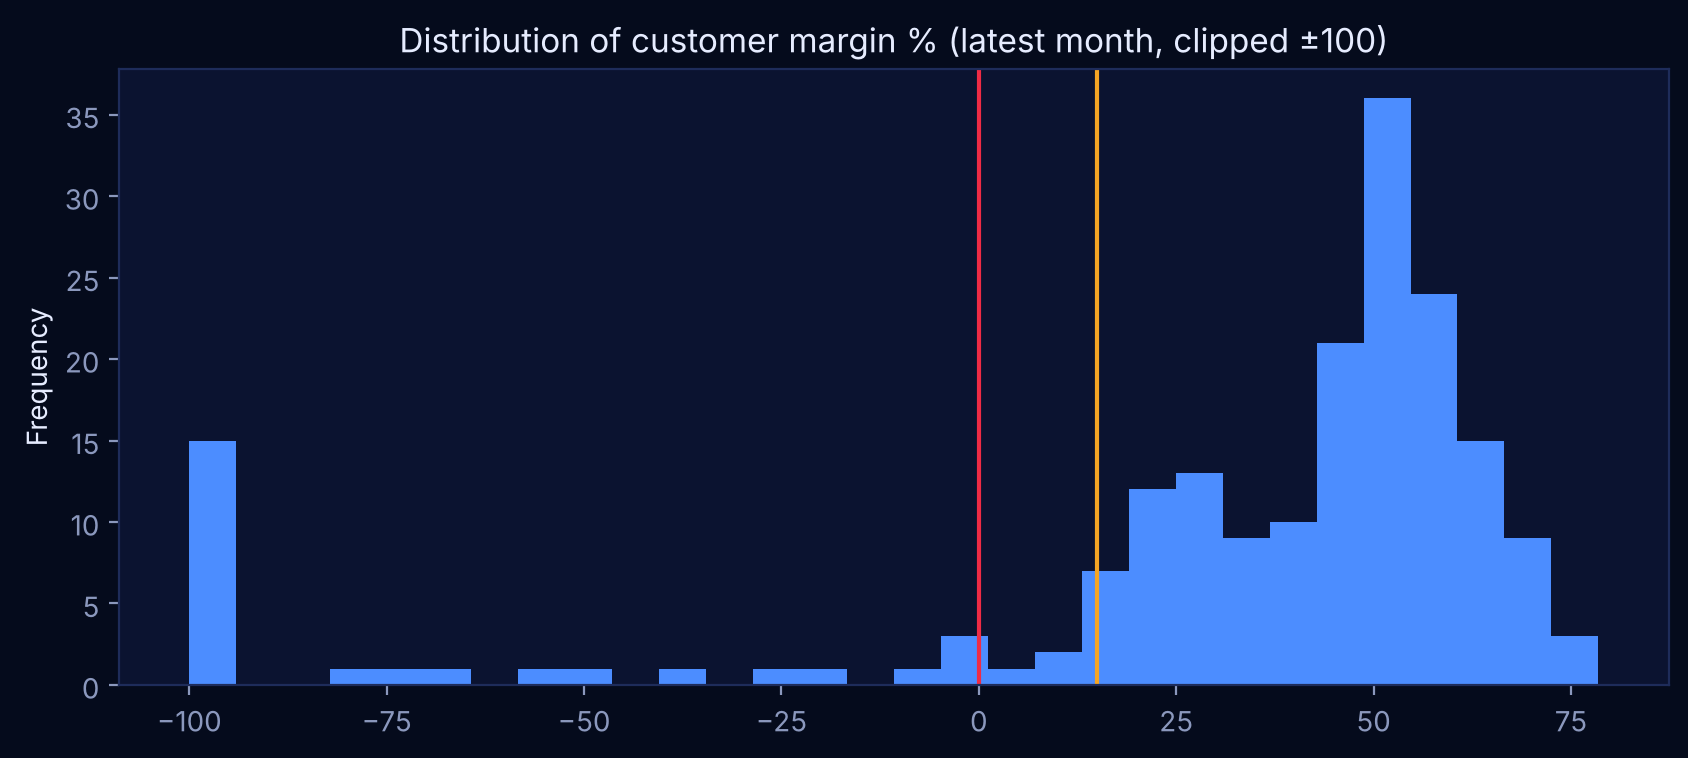

In [5]:
last = e[e.month_start == e.month_start.max()].copy()
last["margin_pct"] = last.margin_pct.astype(float)
ax = last.margin_pct.clip(-100, 100).plot(kind="hist", bins=30, color="#4c8dff", title="Distribution of customer margin % (latest month, clipped ±100)")
ax.axvline(0, color="#ef2b45"); ax.axvline(15, color="#f5a524")
last.profitability.value_counts()

## 4. Least profitable customers (latest month)

In [6]:
last.nsmallest(10, "contribution")[["customer_name", "segment", "region", "net_revenue", "direct_cost", "contribution", "margin_pct"]]

,customer_name,segment,region,net_revenue,direct_cost,contribution,margin_pct
1010,Horizon Networks Inc.,ENTERPRISE,Singapore,"69,375.00","211,498.73","-142,123.73",-204.86
974,Quanta Media Inc.,ENTERPRISE,Delhi NCR,"95,358.40","227,209.88","-131,851.48",-138.27
920,Zenith Analytics Pvt. Ltd.,ENTERPRISE,Dubai,"107,440.00","218,824.71","-111,384.71",-103.67
875,InfiniIT Services,ENTERPRISE,Singapore,"115,199.80","203,167.63","-87,967.83",-76.36
932,Mosaic Infotech Pvt. Ltd.,ENTERPRISE,Mumbai,0.00,"87,633.28","-87,633.28",NaN
983,Radiant Health LLP,ENTERPRISE,Bengaluru,"139,782.40","211,739.82","-71,957.42",-51.48
929,Echo Media LLP,MID_MARKET,Pune,"28,700.00","86,695.50","-57,995.50",-202.07
934,Echo Retail Inc.,ENTERPRISE,Pune,0.00,"54,514.94","-54,514.94",NaN
1047,Vertex Infotech LLP,MID_MARKET,Delhi NCR,"32,913.16","81,483.36","-48,570.20",-147.57
1029,Quill Health Pvt. Ltd.,MID_MARKET,Pune,"43,788.00","88,686.60","-44,898.60",-102.54


## 5. Product profitability

,product_name,month_start,revenue,direct_cost,contribution,margin_pct
25,API Calls,2026-10-01,"1,037,835.90","935,835.00","102,000.90",9.83
26,Analytics Add-on,2026-10-01,"959,870.96","306,801.00","653,069.96",68.04
27,Data Storage,2026-10-01,"186,610.53","384,165.00","-197,554.47",-105.86
28,Platform Core,2026-10-01,"9,398,589.43","4,067,153.00","5,331,436.43",56.73
29,Premium Support,2026-10-01,"1,120,107.99","1,969,109.00","-849,001.01",-75.80


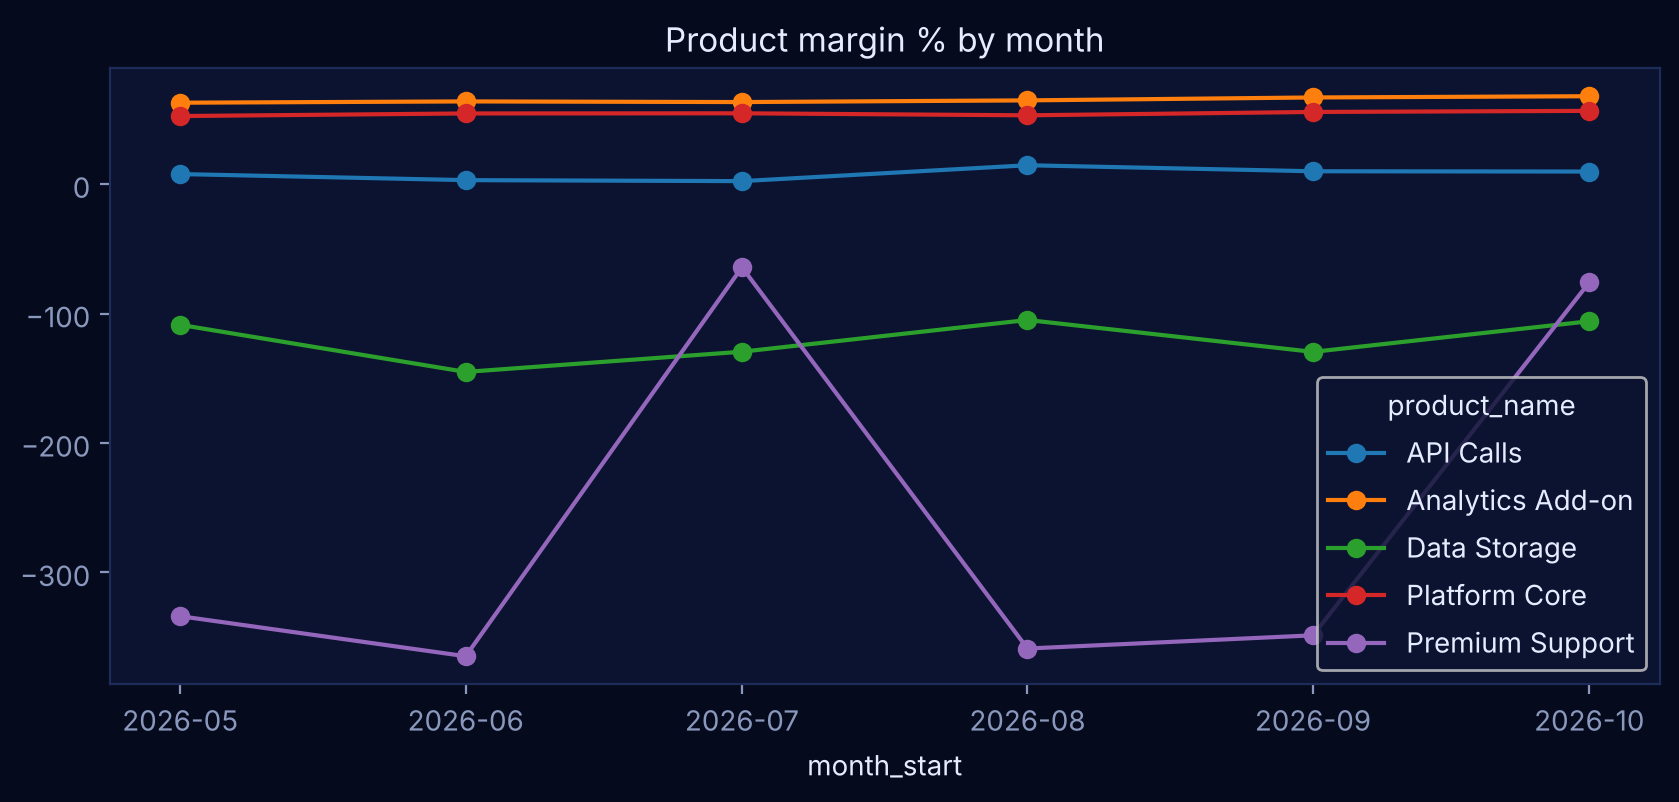

In [7]:
p = q("""SELECT p.product_name, e.month_start, e.revenue, e.direct_cost, e.contribution, e.margin_pct
         FROM reporting.product_economics_monthly e JOIN reporting.dim_product p USING (product_id, tenant_id) ORDER BY 2, 1""")
p.pivot(index="month_start", columns="product_name", values="margin_pct").astype(float).plot(marker="o", title="Product margin % by month")
p[p.month_start == p.month_start.max()]